In [ ]:
import pandas as pd
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from variables import * 
from utils import *

In [ ]:
alimentacion = pd.read_csv("./dataframes/alimentacion_df_limpio1.csv", sep=',')

In [ ]:
sinonimos_DEs_mapa = {}

for de in posibles_DEs:
    nombre_principal = de["nombre_quimico"].lower()
    sinonimos_DEs_mapa[nombre_principal] = nombre_principal  # Mapeamos el nombre principal a sí mismo

    for sinonimo in de["otros_nombres"]:
        sinonimos_DEs_mapa[sinonimo.lower()] = nombre_principal  # Mapeamos cada sinónimo al nombre principal

In [ ]:
alimentacion["ingredients_analysis_tags"].info()

In [ ]:
alimentacion["posibles_DEs_en_ingredientes"] = alimentacion["ingredients_analysis_tags"].apply(busqueda_posibles_DEs, args=(sinonimos_DEs_mapa,))
alimentacion["posibles_DEs_en_aditivos"] = alimentacion["additives_tags"].apply(busqueda_posibles_DEs, args=(sinonimos_DEs_mapa,))

In [ ]:
alimentacion["posibles_DEs_totales"] = alimentacion.apply(combinar_limpiar_posibles_DEs, axis=1)

In [ ]:
# ¿Cuáles son los posibles DEs?
lista_posibles_DEs = []

for fila in alimentacion["posibles_DEs_totales"]:
    for de in fila:
        lista_posibles_DEs.append(de)

todos_los_posibles_DEs = pd.Series(lista_posibles_DEs) # Eliminamos duplicados y convertimos a lista

In [ ]:
todos_los_posibles_DEs.value_counts()

In [ ]:
# contamos cuántos posibles DEs hay en cada fila y lo añadimos como nueva columna
alimentacion["cantidad_posibles_DEs"] = alimentacion["posibles_DEs_totales"].apply(len)

# tiene al menos un DE? booleano
alimentacion["tiene_algun_DE"] = alimentacion["cantidad_posibles_DEs"] > 0

In [ ]:
apilado = alimentacion.groupby("nova_group")[["product_name", "tiene_algun_DE"]].aggregate({
    'product_name': "count",'tiene_algun_DE': 'sum'})

apilado = apilado.rename(columns={"product_name":"cantidad_total_productos", 
                        "tiene_algun_DE":"cantidad_posibles_DEs"})

In [ ]:
apilado["porcentaje_prod_sin_de"] = ((apilado["cantidad_total_productos"] - apilado["cantidad_posibles_DEs"]) / apilado["cantidad_total_productos"]) * 100
apilado["porcentaje_prod_con_de"] = (apilado["cantidad_posibles_DEs"] / apilado["cantidad_total_productos"]) * 100
apilado

In [ ]:
alimentacion.to_csv("./dataframes/alimentacion_df_limpio_DEs.csv", sep=',', index=False, encoding='utf-8')

In [2]:
alimentacion = pd.read_csv("./dataframes/alimentacion_df_limpio_DEs.csv", sep=',')

C:\Users\alexa\AppData\Local\Temp\ipykernel_24140\897800558.py:1: DtypeWarning: Columns (8: categories) have mixed types. Specify dtype option on import or set low_memory=False.
  alimentacion = pd.read_csv("./dataframes/alimentacion_df_limpio_DEs.csv", sep=',')


In [3]:
alimentacion["nutriscore_grade"].value_counts()

nutriscore_grade
unknown           225766
d                  26063
e                  22815
c                  20163
a                  15096
b                  14040
not-applicable      7222
Name: count, dtype: int64

In [4]:
alimentacion[alimentacion["nutriscore_grade"] == "not-applicable"][["product_name", "nutriscore_grade", "nutriscore_score"]].head()

,product_name,nutriscore_grade,nutriscore_score
0,gum cool watermelon,not-applicable,NaN
8,Trident spearmint slim pack,not-applicable,NaN
57,Magnesium bisglycinate,not-applicable,NaN
58,Vitamine B12 500μg - 50 Gélules - Solgar,not-applicable,NaN
77,Balsamic Vinegar,not-applicable,NaN


Los "not-applicable" son alimentos que no se pueden clasificar por normativa.

In [5]:
# Preparar los grupos para el test (excluyendo "Sin dato" para la prueba estadística pura)
df_test = alimentacion[alimentacion['nutriscore_grade'].isin(['a', 'b', 'c', 'd', 'e'])]

# Ejecutar Kruskal-Wallis
grupos = [group['cantidad_posibles_DEs'].values for name, group in df_test.groupby('nutriscore_grade')]
estadistico_h, p_valor = stats.kruskal(*grupos)

print(f"--- RESULTADO ESTADÍSTICO (Hipótesis 2) ---")
print(f"Test de Kruskal-Wallis: p-valor = {p_valor:.2e}")
print(f'Estadístico H: {estadistico_h}')
if p_valor < 0.001:
    print("✅ Conclusión: La diferencia en la carga de DEs entre los distintos Nutri-Scores es ALTAMENTE SIGNIFICATIVA (p < 0.001).")
else:
    print(f"⚠️ Conclusión: El p-valor es {p_valor}. Revisa los datos.")

--- RESULTADO ESTADÍSTICO (Hipótesis 2) ---
Test de Kruskal-Wallis: p-valor = 1.71e-71
Estadístico H: 336.15858577475996
✅ Conclusión: La diferencia en la carga de DEs entre los distintos Nutri-Scores es ALTAMENTE SIGNIFICATIVA (p < 0.001).


In [7]:
selection = alimentacion[["nutriscore_grade", "cantidad_posibles_DEs"]]
selection.head()

,nutriscore_grade,cantidad_posibles_DEs
0,not-applicable,4
1,a,0
2,unknown,0
3,c,0
4,e,0


In [9]:
selection["nutriscore_grade"].value_counts()

nutriscore_grade
unknown           225766
d                  26063
e                  22815
c                  20163
a                  15096
b                  14040
not-applicable      7222
Name: count, dtype: int64

In [11]:
selection.describe(include="all")

,nutriscore_grade,cantidad_posibles_DEs
count,331165,331165.000000
unique,7,NaN
top,unknown,NaN
freq,225766,NaN
mean,NaN,0.030242
std,NaN,0.241612
min,NaN,0.000000
25%,NaN,0.000000
50%,NaN,0.000000
75%,NaN,0.000000


In [12]:
selection.groupby("nutriscore_grade")["cantidad_posibles_DEs"].mean() * 100

nutriscore_grade
a                  6.491786
b                  3.675214
c                  9.140505
d                  8.122626
e                  7.920228
not-applicable    10.648020
unknown            0.878343
Name: cantidad_posibles_DEs, dtype: float64

Inesperadamente, los not-applicable tienen posibles DEs. Vamos a mirar qué categorías son.

In [16]:
not_applicable = alimentacion[alimentacion["nutriscore_grade"] == "not-applicable"][["product_name", "nutriscore_grade", "cantidad_posibles_DEs", "categories_en"]]

In [17]:
porcentaje_con_DEs = (not_applicable["cantidad_posibles_DEs"] > 0).mean() * 100

In [18]:
print(f"El {porcentaje_con_DEs:.1f}% de los productos 'not-applicable' tienen al menos un DE.")


El 5.0% de los productos 'not-applicable' tienen al menos un DE.


In [19]:
not_applicable.head(20)

,product_name,nutriscore_grade,cantidad_posibles_DEs,categories_en
0,gum cool watermelon,not-applicable,4,"Snacks,Sweet snacks,Confectioneries,en:chewing..."
8,Trident spearmint slim pack,not-applicable,5,"Snacks,Sweet snacks,Confectioneries,en:chewing..."
57,Magnesium bisglycinate,not-applicable,0,Dietary supplements
58,Vitamine B12 500μg - 50 Gélules - Solgar,not-applicable,0,Dietary supplements
77,Balsamic Vinegar,not-applicable,0,"Condiments,Vinegars,Balsamic vinegars"
99,Guacamole Mild,not-applicable,0,"Plant-based foods and beverages,Plant-based fo..."
122,Sea Salt Crystals,not-applicable,0,"Condiments,Salts,Sea salts,en:Groceries"
139,Balsamic vinegar,not-applicable,0,"Condiments,Sauces,Vinegars,Balsamic vinegars,S..."
154,Angostura,not-applicable,0,"Beverages and beverages preparations,Beverages..."
266,Tajin Mexican Classic Seasoning 142g,not-applicable,0,"Plant-based foods and beverages,Plant-based fo..."


In [20]:
not_applicable["categories_en"].value_counts().head(30)

categories_en
Dietary supplements                                                                                          920
Beverages and beverages preparations,Beverages,Alcoholic beverages,Beers                                     210
Beverages,Alcoholic beverages,Beers                                                                          200
Baby foods                                                                                                   166
Condiments,Vinegars,Cider vinegars                                                                           164
Snacks,Sweet snacks,Confectioneries,Chewing gums,Sugar-free chewing gum                                      163
Beverages,Alcoholic beverages,Wines,Red wines                                                                153
Condiments,Salts,en:groceries                                                                                148
Beverages,Alcoholic beverages,Wines,White wines                                   

In [21]:
not_applicable.loc[not_applicable["categories_en"].str.endswith("Beers")]

,product_name,nutriscore_grade,cantidad_posibles_DEs,categories_en
277,Dark Rich & Sexy,not-applicable,0,"Beverages,Alcoholic beverages,Beers"
280,Cerveza rubia,not-applicable,0,"Beverages,Alcoholic beverages,Beers"
1590,Premium pils,not-applicable,0,"Beverages and beverages preparations,Beverages..."
1628,Cerveza,not-applicable,0,"Beverages,Alcoholic beverages,Beers"
3059,Cerveza especial,not-applicable,0,"Beverages,Alcoholic beverages,Beers"
...,...,...,...,...
316982,Stella artois,not-applicable,0,"Beverages and beverages preparations,Beverages..."
316983,Brahma,not-applicable,0,"Beverages and beverages preparations,Beverages..."
329535,Desperados,not-applicable,0,"Beverages and beverages preparations,Beverages..."
329837,Cerveza Tostada Turia,not-applicable,0,"Beverages and beverages preparations,Beverages..."


In [22]:
not_applicable.loc[not_applicable["categories_en"].str.contains("supplements", case=False), "categories_en"] = "Suplementos"
not_applicable.loc[not_applicable["categories_en"].str.contains("beers", case=False), "categories_en"] = "Bebidas alcohólicas: Cervezas"
not_applicable.loc[not_applicable["categories_en"].str.contains("baby", case=False), "categories_en"] = "Comida para bebés"
not_applicable.loc[not_applicable["categories_en"].str.contains("vinegars", case=False), "categories_en"] = "Condimentos: Vinagres"
not_applicable.loc[not_applicable["categories_en"].str.contains("wines", case=False), "categories_en"] = "Bebidas alcohólicas: Vinos"
not_applicable.loc[not_applicable["categories_en"].str.contains("gum", case=False), "categories_en"] = "Dulces: Chicles"
not_applicable.loc[not_applicable["categories_en"].str.contains("food colorings", case=False), "categories_en"] = "Colorantes"
not_applicable.loc[not_applicable["categories_en"].str.contains("condiments", case=False), "categories_en"] = "Condimentos"

In [23]:
categorias = ["Condimentos", "Dulces: Chicles", "Bebidas alcohólicas: Vinos", "Condimentos: Vinagres", "Comida para bebés", "Bebidas alcohólicas: Cervezas", "Suplementos", "Colorantes"]

In [24]:
not_applicable.loc[not_applicable["categories_en"].isin(categorias) == False, "categories_en"] = "Otras categorías"

In [25]:
not_applicable["categories_en"].value_counts().head(30)

categories_en
Condimentos                      1635
Suplementos                      1220
Otras categorías                 1156
Bebidas alcohólicas: Vinos       1025
Bebidas alcohólicas: Cervezas     681
Condimentos: Vinagres             632
Comida para bebés                 502
Dulces: Chicles                   302
Colorantes                         69
Name: count, dtype: int64

In [26]:
not_applicable.head()

,product_name,nutriscore_grade,cantidad_posibles_DEs,categories_en
0,gum cool watermelon,not-applicable,4,Dulces: Chicles
8,Trident spearmint slim pack,not-applicable,5,Dulces: Chicles
57,Magnesium bisglycinate,not-applicable,0,Suplementos
58,Vitamine B12 500μg - 50 Gélules - Solgar,not-applicable,0,Suplementos
77,Balsamic Vinegar,not-applicable,0,Condimentos: Vinagres


In [27]:
not_applicable.groupby("categories_en")["cantidad_posibles_DEs"].sum()

categories_en
Bebidas alcohólicas: Cervezas      7
Bebidas alcohólicas: Vinos         7
Colorantes                        28
Comida para bebés                  0
Condimentos                       33
Condimentos: Vinagres              2
Dulces: Chicles                  427
Otras categorías                 182
Suplementos                       83
Name: cantidad_posibles_DEs, dtype: int64

In [28]:
not_applicable.groupby("categories_en")["cantidad_posibles_DEs"].mean() * 100

categories_en
Bebidas alcohólicas: Cervezas      1.027900
Bebidas alcohólicas: Vinos         0.682927
Colorantes                        40.579710
Comida para bebés                  0.000000
Condimentos                        2.018349
Condimentos: Vinagres              0.316456
Dulces: Chicles                  141.390728
Otras categorías                  15.743945
Suplementos                        6.803279
Name: cantidad_posibles_DEs, dtype: float64

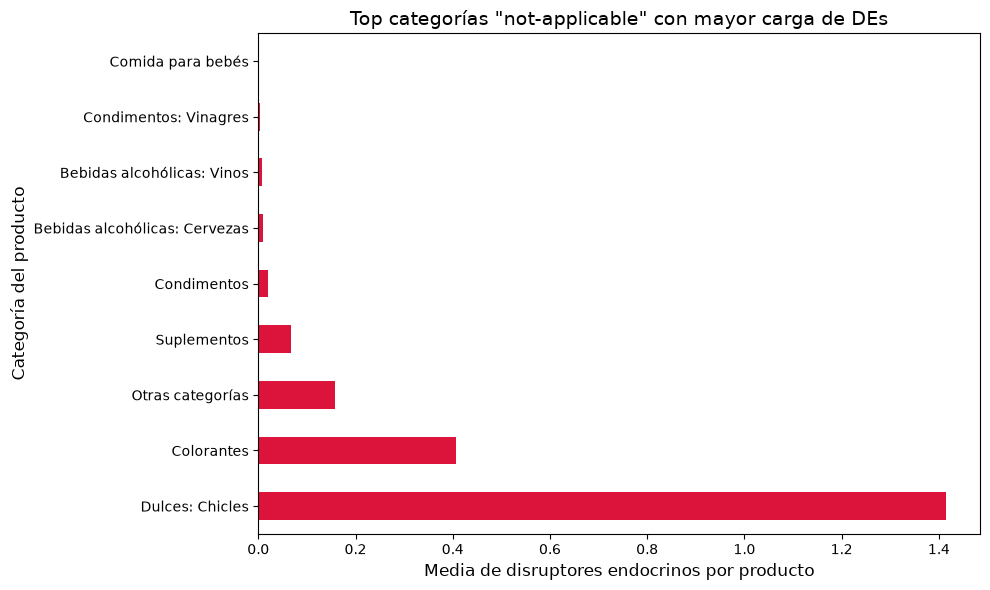

In [29]:
# 2. Aseguramos que no haya categorías vacías para que no rompa el gráfico
not_applicable['categories_en'] = not_applicable['categories_en'].fillna("Sin categoría")

# 3. Calculamos la MEDIA de DEs por cada categoría
media_por_categoria = not_applicable.groupby('categories_en')['cantidad_posibles_DEs'].mean()

# 4. Ordenamos de mayor a menor y nos quedamos con las 10 categorías con más DEs
top_categorias = media_por_categoria.sort_values(ascending=False).head(10)

# 5. Dibujamos el gráfico de barras horizontales
top_categorias.plot(kind='barh', figsize=(10, 6), color='crimson')

plt.title('Top categorías "not-applicable" con mayor carga de DEs', fontsize=14)
plt.xlabel('Media de disruptores endocrinos por producto', fontsize=12)
plt.ylabel('Categoría del producto', fontsize=12)
plt.tight_layout()
plt.show()

# Análisis multivariante

In [30]:
alimentacion.groupby(["nova_group", "nutriscore_grade"])["cantidad_posibles_DEs"].sum()

nova_group  nutriscore_grade
0.0         a                      1
            b                      3
            c                      0
            d                      9
            e                     14
            not-applicable         0
            unknown               98
1.0         a                      2
            b                      2
            c                      0
            d                      0
            e                      1
            not-applicable         0
            unknown                0
2.0         a                      0
            b                      3
            c                      1
            d                      0
            e                      0
            not-applicable         0
            unknown                0
3.0         a                     63
            b                     52
            c                     59
            d                    108
            e                    184
         

In [31]:
alimentacion.pivot_table('cantidad_posibles_DEs', index='nutriscore_grade', columns='nova_group', aggfunc='sum')

nova_group,0.0,1.0,2.0,3.0,4.0
nutriscore_grade,,,,,
a,1,2,0,63,914
b,3,2,3,52,456
c,0,0,1,59,1783
d,9,0,0,108,2000
e,14,1,0,184,1608
not-applicable,0,0,0,3,766
unknown,98,0,0,28,1857


In [32]:
alimentacion.pivot_table(index='nutriscore_grade', columns='nova_group',
                    aggfunc={'cantidad_posibles_DEs': 'sum'})

cantidad_posibles_DEs                   
nova_group                         0.0 1.0 2.0  3.0   4.0
nutriscore_grade                                         
a                                    1   2   0   63   914
b                                    3   2   3   52   456
c                                    0   0   1   59  1783
d                                    9   0   0  108  2000
e                                   14   1   0  184  1608
not-applicable                       0   0   0    3   766
unknown                             98   0   0   28  1857

In [35]:
alimentacion[(alimentacion["nova_group"] == 1) & (alimentacion["nutriscore_grade"] == "e")][["product_name", "nutriscore_score", "categories", "categories_en", "ingredients_text"]]

,product_name,nutriscore_score,categories,categories_en,ingredients_text
228,Apple chips,19.0,NaN,"Plant-based foods and beverages,Plant-based fo...",Rondelles de pommes séchées avec épluchures. P...
1034,Hareng,20.0,NaN,"Seafood,Fishes and their products,Canned foods...","Hareng (Clupea harengus), pêché dans l'Atlanti..."
1631,Original Nectar Pera,12.0,NaN,"Beverages and beverages preparations,Plant-bas...","50% polme de pera, água, a car, regulador de a..."
2247,Dijon Originale Mostaza Mostarda,21.0,NaN,"Condiments,Sauces,Mustards,Dijon mustards","Vann, SENNEPSFRØ (30%), vineddik, salt, surhet..."
3176,100% PUR JUS ORANGE Avec pulpe,10.0,NaN,"Beverages and beverages preparations,Plant-bas...",Jus d'orange dont pulpe (4%).
...,...,...,...,...,...
307702,Queso Camembert,20.0,NaN,"en:Lácteos,en:Quesos,en:Quesos Camembert","LECHE PASTEURIZADA, CLORURO DE SODIO, CULTIVOS..."
311657,Sirope De Agave,19.0,NaN,"Sweeteners,Syrups,Simple syrups,Agave syrups,e...",Sirope de agave
318740,Vivo Néctar Naranja,12.0,NaN,"Beverages and beverages preparations,Plant-bas...","Agua, concentrado de manzana, concentrado de n..."
319906,Smoothie Tropical,14.0,NaN,"Beverages and beverages preparations,Plant-bas...",TROPICAL SMOOTHIE PR 100ML MEZCLA DE ZUMOS Y P...


In [47]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Asegurarnos de que los datos estén limpios y listos para el modelo
df_model = df_filtrado.dropna(subset=['nova_group', 'nutriscore_grade', 'tiene_DE']).copy()

# Convertimos la variable objetivo (True/False) en 1 y 0 para que la regrese logística la entienda
df_model['tiene_DE_int'] = df_model['tiene_DE'].astype(int)

# Nos aseguramos de que nova_group sea tratado como categoría (por si acaso es numérico entero)
df_model['nova_group'] = df_model['nova_group'].astype('category')
df_model['nutriscore_grade'] = df_model['nutriscore_grade'].astype('category')

# 2. Ajustar el modelo de Regresión Logística Multivariante
# 'C(nova_group)' y 'C(nutriscore_grade)' le indican a statsmodels que son variables categóricas
modelo = smf.logit("tiene_DE_int ~ C(nova_group) + C(nutriscore_grade)", data=df_model).fit()

# Imprimir el resumen estadístico completo del modelo
print(modelo.summary())

# 3. Calcular los Odds Ratios (OR) y sus intervalos de confianza al 95%
# Los coeficientes de la regresión logística están en escala logarítmica, al aplicar np.exp() obtenemos los Odds Ratios
params = modelo.params
conf = modelo.conf_int()
conf['OR'] = np.exp(params)
conf.columns = ['IC_inf', 'IC_sup', 'Odds_Ratio']

# Añadimos el p-valor para ver qué variables son estadísticamente significativas
resultado_or = pd.DataFrame({
    'Odds Ratio': conf['Odds_Ratio'],
    'IC 95% Inferior': np.exp(conf['IC_inf']),
    'IC 95% Superior': np.exp(conf['IC_sup']),
    'P-valor': modelo.pvalues
})

print("\n--- ODDS RATIOS Y SIGNIFICANCIA ESTADÍSTICA ---")
print(resultado_or)

Optimization terminated successfully.
         Current function value: 0.334233
         Iterations 11
                           Logit Regression Results                           
Dep. Variable:           tiene_DE_int   No. Observations:                39689
Model:                          Logit   Df Residuals:                    39681
Method:                           MLE   Df Model:                            7
Date:               ma., 10 nov. 2026   Pseudo R-squ.:                  0.1573
Time:                        16:28:50   Log-Likelihood:                -13265.
converged:                       True   LL-Null:                       -15742.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -6.8069      0.448    -15.205      0.000      -7.68

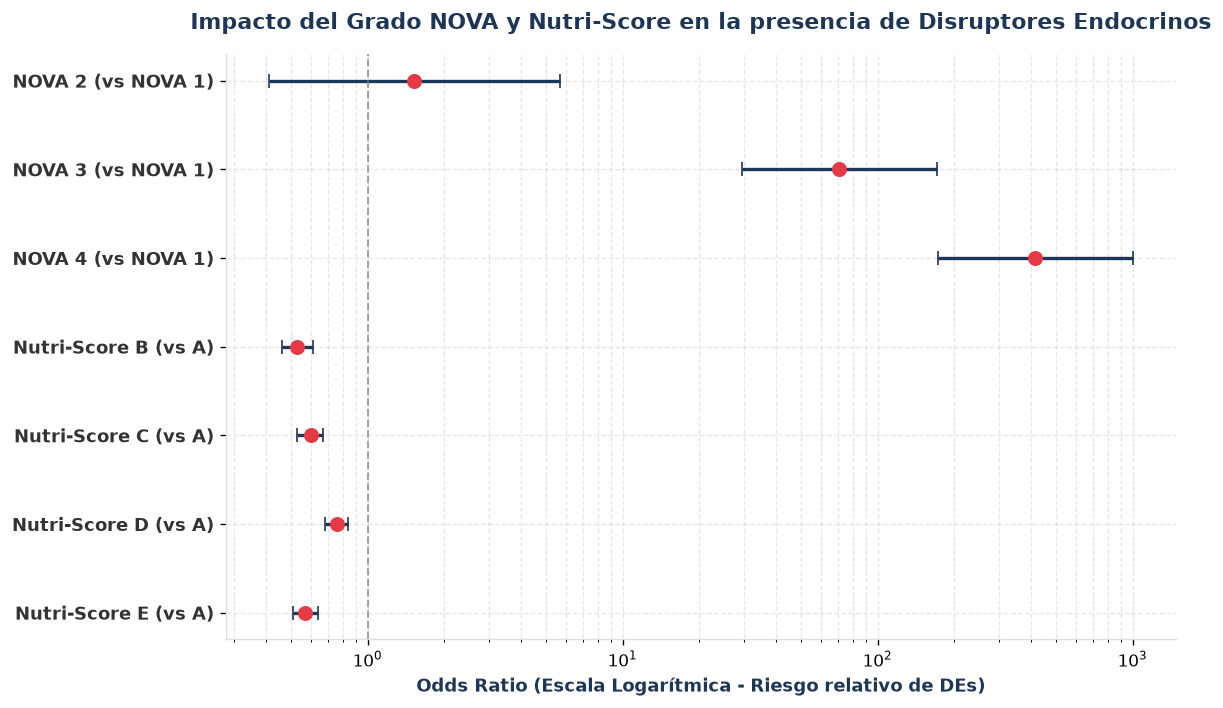

In [48]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Creamos un DataFrame con los resultados clave que obtuviste de la regresión
# (Separamos las variables NOVA y Nutri-Score para ordenarlas visualmente)
datos_or = pd.DataFrame({
    'Variable': [
        'NOVA 2 (vs NOVA 1)', 
        'NOVA 3 (vs NOVA 1)', 
        'NOVA 4 (vs NOVA 1)',
        'Nutri-Score B (vs A)', 
        'Nutri-Score C (vs A)', 
        'Nutri-Score D (vs A)', 
        'Nutri-Score E (vs A)'
    ],
    'OR': [1.52, 70.81, 415.66, 0.53, 0.60, 0.76, 0.57],
    'IC_inf': [0.41, 29.28, 172.45, 0.46, 0.53, 0.68, 0.51],
    'IC_sup': [5.70, 171.25, 1001.85, 0.61, 0.67, 0.84, 0.64]
})

# 2. Configuramos la figura
fig, ax = plt.subplots(figsize=(10, 6), dpi=120)

# Invertimos el orden para que los elementos más importantes (NOVA 4) queden arriba
y_pos = np.arange(len(datos_or))
datos_or = datos_or.iloc[::-1].reset_index(drop=True)
y_pos_rev = np.arange(len(datos_or))

# 3. Dibujamos los puntos (OR) y las barras de error (Intervalos de Confianza)
# Usamos escala logarítmica en el eje X debido a la enorme diferencia de magnitud (de 0.5 a 400+)
ax.errorbar(
    datos_or['OR'], y_pos_rev,
    xerr=[datos_or['OR'] - datos_or['IC_inf'], datos_or['IC_sup'] - datos_or['OR']],
    fmt='o', color='#E63946', ecolor='#1D3557', elinewidth=2, capsize=4, markersize=8
)

# Línea vertical de referencia en OR = 1 (Sin efecto / Sin cambio de riesgo)
ax.axvline(x=1, color='gray', linestyle='--', linewidth=1.2, alpha=0.7)

# 4. Estética y formato del gráfico
ax.set_yticks(y_pos_rev)
ax.set_yticklabels(datos_or['Variable'], fontsize=11, fontweight='bold', color='#333333')
ax.set_xscale('log')  # Imprescindible escala logarítmica por el salto masivo en NOVA 4

ax.set_xlabel('Odds Ratio (Escala Logarítmica - Riesgo relativo de DEs)', fontsize=11, fontweight='bold', color='#1D3557')
ax.set_title('Impacto del Grado NOVA y Nutri-Score en la presencia de Disruptores Endocrinos', fontsize=13, fontweight='bold', color='#1D3557', pad=15)

# Limpiar diseño (Spines)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#dddddd')
ax.spines['bottom'].set_color('#dddddd')
ax.grid(True, which="both", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

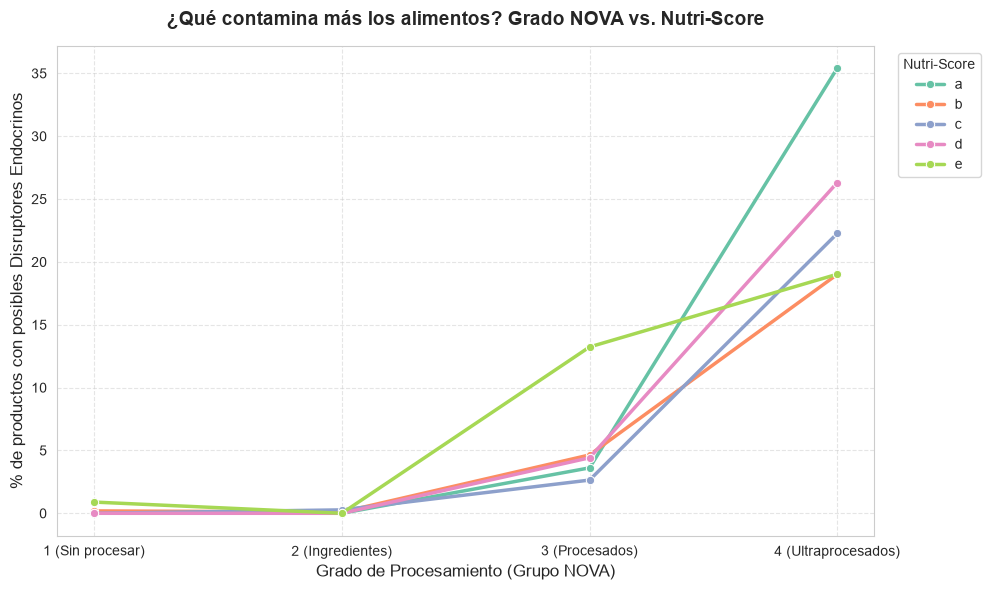

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Preparamos los datos: calcular el % de DEs por Grupo NOVA y Nutri-Score
df_plot = df_filtrado.copy()
df_plot['tiene_DE'] = df_plot['cantidad_posibles_DEs'] > 0

df_agg = df_plot.groupby(['nova_group', 'nutriscore_grade'])['tiene_DE'].mean().reset_index()
df_agg['Porcentaje'] = df_agg['tiene_DE'] * 100

# 2. Configuración del gráfico de líneas/puntos (muy limpio para público general)
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=df_agg, 
    x='nova_group', 
    y='Porcentaje', 
    hue='nutriscore_grade', 
    marker='o', 
    linewidth=2.5,
    palette='Set2'
)

plt.title('¿Qué contamina más los alimentos? Grado NOVA vs. Nutri-Score', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Grado de Procesamiento (Grupo NOVA)', fontsize=12)
plt.ylabel('% de productos con posibles Disruptores Endocrinos', fontsize=12)
plt.xticks([1, 2, 3, 4], ['1 (Sin procesar)', '2 (Ingredientes)', '3 (Procesados)', '4 (Ultraprocesados)'])
plt.legend(title='Nutri-Score', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()